# 02 · Clinical audit and receptor status

**Goal:** Audit the clinical tables on their own (structure, missing values, conflicts), then build **one clinical row per patient** including ER, PR and HER2 status.

**Inputs:** `clinical.tsv`, `follow_up.tsv`, `pathology_detail.tsv`, `slide.tsv`.
**Output:** `data/processed/clinical_patient.csv` (one row per patient).

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

def find_project_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "notebooks").is_dir() and (folder / "data" / "raw" / "RNA").is_dir():
            return folder.resolve()
    raise FileNotFoundError("Project root not found (needs notebooks/ and data/raw/RNA/).")

ROOT = find_project_root()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

def find_folder(prefix):
    hits = [p for p in RAW.iterdir() if p.is_dir() and p.name.lower().startswith(prefix.lower())]
    if len(hits) != 1:
        raise RuntimeError(f"Expected exactly one folder starting with {prefix!r}; found {[p.name for p in hits]}")
    return hits[0]

RNA_DIR = find_folder("RNA")
CLINICAL_DIR = find_folder("clinical.project-tcga-brca")
BIOSPECIMEN_DIR = find_folder("biospecimen.project-tcga-brca")

def read_gdc(path):
    """Read a GDC TSV as text; the GDC missing marker "'--" and empty cells become NaN."""
    df = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False, low_memory=False)
    return df.replace({"'--": np.nan, "": np.nan})

print("Project root:", ROOT)

import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# One colour per meaning in every figure: blue = positive / included, orange = negative, grey = neutral.
POS, NEG, GREY = "#2F6DB5", "#D9822B", "#6B7280"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 10,
})

def save_fig(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))

Project root: D:\University\ترم 3\آمار و کاربرد آن\tcga-brca-statistics


## 1. Structure of the clinical tables

`clinical.tsv` is nested (patient × diagnosis × treatment), so a patient appears on many rows. `follow_up.tsv` is nested too (patient × follow-up × molecular test). Only `pathology_detail.tsv` has one row per patient.

In [13]:
clin = read_gdc(CLINICAL_DIR / "clinical.tsv")
fu   = read_gdc(CLINICAL_DIR / "follow_up.tsv")
pdx  = read_gdc(CLINICAL_DIR / "pathology_detail.tsv")
PID = "cases.submitter_id"

rows = []
for name, df in [("clinical", clin), ("follow_up", fu), ("pathology_detail", pdx)]:
    per = df[PID].value_counts()
    rows.append({"table": name, "rows": len(df), "patients": df[PID].nunique(), "median rows/patient": per.median(),
                 "max rows/patient": per.max(), "exact duplicate rows": int(df.duplicated().sum())})
display(pd.DataFrame(rows))

,table,rows,patients,median rows/patient,max rows/patient,exact duplicate rows
0,clinical,5546,1098,5.0,40,0
1,follow_up,9427,1096,8.0,25,0
2,pathology_detail,1096,1096,1.0,1,0


## 2. Which diagnosis is "the" tumour?

A patient can have several diagnosis records (prior primary, synchronous primary, metastasis). Tumour variables (stage, histology) are taken from the **one diagnosis flagged `diagnosis_is_primary_disease == "true"`**, so values from different diagnoses are never mixed.

In [14]:
n_prim_flag = (clin.drop_duplicates(["diagnoses.diagnosis_id"])
               .query("`diagnoses.diagnosis_is_primary_disease` == 'true'").groupby(PID).size())
all_pat = clin[PID].nunique()
print(f"Patients in clinical.tsv: {all_pat}")
print(f"... with exactly one primary-disease diagnosis: {(n_prim_flag == 1).sum()}")
print(f"... with more than one: {(n_prim_flag > 1).sum()}")
no_flag = sorted(set(clin[PID]) - set(n_prim_flag.index))
print(f"... with none flagged: {len(no_flag)} {no_flag}")
assert (n_prim_flag > 1).sum() == 0

# Why this matters: stage differs between a patient's diagnoses
stage_all = clin.groupby(PID)["diagnoses.ajcc_pathologic_stage"].nunique()
print(f"\nPatients whose stage differs between their diagnosis records: {(stage_all > 1).sum()} -> resolved by using the primary diagnosis only")

Patients in clinical.tsv: 1098
... with exactly one primary-disease diagnosis: 1096
... with more than one: 0
... with none flagged: 2 ['TCGA-A7-A0DC', 'TCGA-BH-A0B2']

Patients whose stage differs between their diagnosis records: 21 -> resolved by using the primary diagnosis only


## 3. One row per patient: demographics, diagnosis, pathology

Demographic fields are constant within a patient (checked below).

In [15]:
const_cols = ["demographic.age_at_index", "demographic.sex_at_birth", "demographic.race", "demographic.vital_status", "demographic.days_to_death"]
nconf = {c: int((clin.groupby(PID)[c].nunique() > 1).sum()) for c in const_cols}
print("Patients with conflicting values within the demographic fields:", nconf)

dem = clin.groupby(PID).agg(age=("demographic.age_at_index", "first"), sex=("demographic.sex_at_birth", "first"),
                            race=("demographic.race", "first"), vital_status=("demographic.vital_status", "first"),
                            days_to_death=("demographic.days_to_death", "first"))
dem[["age", "days_to_death"]] = dem[["age", "days_to_death"]].apply(pd.to_numeric)

prim = (clin[clin["diagnoses.diagnosis_is_primary_disease"].eq("true")]
        .drop_duplicates("diagnoses.diagnosis_id").set_index(PID))
diag = pd.DataFrame({
    "stage": prim["diagnoses.ajcc_pathologic_stage"].str.extract(r"^Stage\s+(IV|III|II|I|0)")[0],
    "t_stage": prim["diagnoses.ajcc_pathologic_t"].str.extract(r"^(T[0-4]|Tis|TX)")[0],
    "n_stage": prim["diagnoses.ajcc_pathologic_n"].str.extract(r"^(N[0-3]|NX)")[0],
    "histology": prim["diagnoses.primary_diagnosis"],
    "year_of_diagnosis": pd.to_numeric(prim["diagnoses.year_of_diagnosis"]),
})
nodes = pdx.set_index(PID)[["pathology_details.lymph_nodes_positive", "pathology_details.lymph_nodes_tested"]] \
           .apply(pd.to_numeric).set_axis(["lymph_nodes_positive", "lymph_nodes_tested"], axis=1)
print("pathology_detail rows per patient == 1:", pdx[PID].is_unique)

Patients with conflicting values within the demographic fields: {'demographic.age_at_index': 0, 'demographic.sex_at_birth': 0, 'demographic.race': 0, 'demographic.vital_status': 0, 'demographic.days_to_death': 0}
pathology_detail rows per patient == 1: True


## 4. Receptor status (ER, PR, HER2)

ER, PR and HER2 are **not** in `clinical.tsv`; they are `molecular_tests` rows in `follow_up.tsv` (`gene_symbol` = `ESR1`, `PGR`, `ERBB2`). Rules, fixed before looking at any result:

| Variable | Rule |
|---|---|
| ER | `ESR1` IHC, Positive or Negative |
| PR | `PGR` IHC, Positive or Negative |
| HER2 | `ERBB2` **FISH** if Positive/Negative; otherwise `ERBB2` **IHC** if Positive/Negative |
| Missing | Equivocal, non-categorical results (e.g. FISH copy number only), or **conflicting repeated tests** for the same patient |

IHC 2+ for HER2 is reported as *Equivocal* in these data and, by ASCO/CAP logic, needs FISH; without FISH it stays missing.

In [16]:
mt = fu[fu["molecular_tests.gene_symbol"].isin(["ESR1", "PGR", "ERBB2"])].copy()
mt = mt.rename(columns={"molecular_tests.gene_symbol": "gene", "molecular_tests.molecular_analysis_method": "method",
                        "molecular_tests.test_result": "result"})
print("Receptor test rows:", len(mt), "| patients with at least one:", mt[PID].nunique())
display(mt.groupby(["gene", "method", "result"]).size().rename("rows").to_frame())

# Can the tests be tied to the primary tumour / diagnosis time?
timing_cols = [c for c in ["molecular_tests.days_to_test", "molecular_tests.timepoint_category",
                           "follow_ups.timepoint_category", "follow_ups.days_to_follow_up"] if c in mt]
print("\nNon-missing timing fields among receptor test rows:")
print({c: int(mt[c].notna().sum()) for c in timing_cols}, "of", len(mt), "rows")

Receptor test rows: 3909 | patients with at least one: 1049


rows
gene  method result                    
ERBB2 FISH   Copy Number Reported   104
             Equivocal                9
             Negative               344
             Positive                79
             Test Value Reported    241
             Unknown                  1
      IHC    Equivocal              196
             Negative               588
             Positive               166
ESR1  IHC    Equivocal                2
             Negative               257
             Positive               833
PGR   IHC    Equivocal                4
             Negative               365
             Positive               720


Non-missing timing fields among receptor test rows:
{'molecular_tests.days_to_test': 0, 'molecular_tests.timepoint_category': 0, 'follow_ups.timepoint_category': 0, 'follow_ups.days_to_follow_up': 0} of 3909 rows


**Limitation recorded.** The receptor rows carry **no date and no timepoint**, so the file cannot prove that a result belongs to the primary tumour at diagnosis (rather than to a later test). The analysis assumes it does; this is listed as a limitation.

In [17]:
def per_patient(gene, method):
    """Consensus result per patient; repeated tests that disagree become 'Conflict'."""
    t = mt[(mt["gene"] == gene) & (mt["method"] == method) & mt["result"].isin(["Positive", "Negative", "Equivocal"])]
    return t.groupby(PID)["result"].agg(lambda s: s.iloc[0] if s.nunique() == 1 else "Conflict")

er_r, pr_r = per_patient("ESR1", "IHC"), per_patient("PGR", "IHC")
her2_ihc_r, her2_fish_r = per_patient("ERBB2", "IHC"), per_patient("ERBB2", "FISH")

raw = pd.DataFrame({"ER IHC": er_r.value_counts(), "PR IHC": pr_r.value_counts(),
                    "HER2 IHC": her2_ihc_r.value_counts(), "HER2 FISH": her2_fish_r.value_counts()}).fillna(0).astype(int)
raw.loc["patients with any categorical result"] = [len(er_r), len(pr_r), len(her2_ihc_r), len(her2_fish_r)]
display(raw)

idx = dem.index
definite = lambda s: s.reindex(idx).where(lambda x: x.isin(["Positive", "Negative"]))
rec = pd.DataFrame(index=idx)
rec["ER"], rec["PR"] = definite(er_r), definite(pr_r)
fish, ihc = definite(her2_fish_r), definite(her2_ihc_r)
rec["HER2"] = fish.combine_first(ihc)
fish_conflict = her2_fish_r.reindex(idx).eq("Conflict")
rec.loc[fish_conflict, "HER2"] = np.nan
rec["HER2_source"] = np.where(rec["HER2"].isna(), None, np.where(fish.notna(), "FISH", "IHC"))

# Why is a status missing? (one reason per patient)
def reason(gene, results):
    tested = set(mt.loc[mt["gene"] == gene, PID])
    out = pd.Series("no test recorded", index=idx)
    out[out.index.isin(tested)] = "only non-categorical result"
    for r_name, lab in [("Equivocal", "equivocal, no definite result"), ("Conflict", "conflicting repeated tests")]:
        out[out.index.isin(results[results == r_name].index)] = lab
    return out

er_any, pr_any = er_r, pr_r
her2_any = pd.concat([her2_fish_r, her2_ihc_r]).groupby(level=0).agg(lambda s: "Conflict" if "Conflict" in set(s) else ("Equivocal" if "Equivocal" in set(s) else "ok"))
miss = pd.DataFrame({
    "ER": reason("ESR1", er_any).where(rec["ER"].isna(), "available"),
    "PR": reason("PGR", pr_any).where(rec["PR"].isna(), "available"),
    "HER2": reason("ERBB2", her2_any).where(rec["HER2"].isna(), "available")})
for r in ["ER", "PR", "HER2"]:
    rec[f"{r}_pos"] = rec[r].map({"Positive": 1.0, "Negative": 0.0})
rec["HR"] = np.where((rec["ER"] == "Positive") | (rec["PR"] == "Positive"), "Positive",
                     np.where((rec["ER"] == "Negative") & (rec["PR"] == "Negative"), "Negative", None))
sym = {"Positive": "+", "Negative": "-"}
rec["ER_HER2"] = np.where(rec["ER"].notna() & rec["HER2"].notna(),
                          "ER" + rec["ER"].map(sym).fillna("") + "/HER2" + rec["HER2"].map(sym).fillna(""), None)
rec["subtype_surrogate"] = np.select(
    [rec["HER2"] == "Positive", (rec["HR"] == "Positive") & (rec["HER2"] == "Negative"),
     (rec["HR"] == "Negative") & (rec["HER2"] == "Negative")],
    ["HER2-positive", "HR+/HER2-", "Triple-negative"], default="")
rec["subtype_surrogate"] = rec["subtype_surrogate"].replace("", np.nan)

print("\nFinal status availability (all patients in clinical.tsv) and reasons for missing:")
display(pd.concat({k: miss[k].value_counts() for k in miss}, axis=1).fillna(0).astype(int))
print("HER2 source:"); display(rec["HER2_source"].value_counts(dropna=False).to_frame("patients"))

,ER IHC,PR IHC,HER2 IHC,HER2 FISH
result,,,,
Conflict,8,5,10,1
Equivocal,2,4,185,9
Negative,237,343,564,337
Positive,801,695,164,77
patients with any categorical result,1048,1047,923,424



Final status availability (all patients in clinical.tsv) and reasons for missing:


,ER,PR,HER2
available,1038,1038,958
no test recorded,50,51,114
conflicting repeated tests,8,5,2
"equivocal, no definite result",2,4,24


HER2 source:


,patients
HER2_source,
IHC,544
FISH,414
NaN,140


## 5. Follow-up context and tumour-cell fraction

Used later only to **describe** included vs excluded patients. "Last contact" is the follow-up row with `timepoint_category == "Last Contact"`; follow-up length differs between patients, so *Tumor Free* only means no tumour was reported up to that date. The slide table gives the pathologist's **percentage of tumour nuclei** per slide; this is not tumour purity.

In [18]:
fu["days"] = pd.to_numeric(fu["follow_ups.days_to_follow_up"], errors="coerce")
last = (fu[fu["follow_ups.timepoint_category"].eq("Last Contact")].sort_values("days", ascending=False)
        .drop_duplicates(PID).set_index(PID))
fup = pd.DataFrame({"last_contact_days": last["days"],
                    "last_contact_response": last["follow_ups.disease_response"].where(
                        last["follow_ups.disease_response"].isin(["TF-Tumor Free", "WT-With Tumor"]))})
fup["max_followup_days"] = fu.groupby(PID)["days"].max()

slide = read_gdc(BIOSPECIMEN_DIR / "slide.tsv")
slide["sample_submitter_id"] = slide["slides.submitter_id"].str[:16]                 # e.g. TCGA-A2-A04Q-01A
slide["tumor_nuclei_pct"] = pd.to_numeric(slide["slides.percent_tumor_nuclei"], errors="coerce")
nuclei = slide.groupby("sample_submitter_id")["tumor_nuclei_pct"].mean().rename("tumor_nuclei_pct")
print("Samples with a tumour-nuclei estimate:", int(nuclei.notna().sum()), "of", slide["sample_submitter_id"].nunique())

Samples with a tumour-nuclei estimate: 1262 of 2348


## 6. Clinical patient table and its audit

In [19]:
clinical_patient = dem.join(diag).join(rec).join(fup).join(nodes)
clinical_patient.index.name = "patient_submitter_id"
clinical_patient = clinical_patient.reset_index()
assert clinical_patient["patient_submitter_id"].is_unique
print("Clinical patient table:", clinical_patient.shape)

# Ranges and logical checks
print(f"\nAge at index: min {clinical_patient['age'].min():.0f}, median {clinical_patient['age'].median():.0f}, max {clinical_patient['age'].max():.0f}"
      f" | missing {clinical_patient['age'].isna().sum()}")
print("Sex:", clinical_patient["sex"].value_counts(dropna=False).to_dict())
dead = clinical_patient["vital_status"].eq("Dead")
print("Dead without days_to_death:", int((dead & clinical_patient["days_to_death"].isna()).sum()),
      "| alive with days_to_death:", int((~dead & clinical_patient["days_to_death"].notna()).sum()))
print("Negative follow-up days:", int((clinical_patient["last_contact_days"] < 0).sum()))

audit_vars = ["age", "sex", "race", "vital_status", "stage", "t_stage", "n_stage", "histology", "ER", "PR", "HER2",
              "last_contact_response", "lymph_nodes_positive"]
miss_tab = pd.DataFrame({"missing": clinical_patient[audit_vars].isna().sum(),
                         "missing %": (100 * clinical_patient[audit_vars].isna().mean()).round(1)})
display(miss_tab)

Clinical patient table: (1098, 26)

Age at index: min 26, median 58, max 89 | missing 1
Sex: {'female': 1085, 'male': 12, nan: 1}
Dead without days_to_death: 1 | alive with days_to_death: 0
Negative follow-up days: 0


,missing,missing %
age,1,0.1
sex,1,0.1
race,1,0.1
vital_status,1,0.1
stage,26,2.4
t_stage,2,0.2
n_stage,2,0.2
histology,2,0.2
ER,60,5.5
PR,60,5.5


saved figures\02_clinical_audit.png


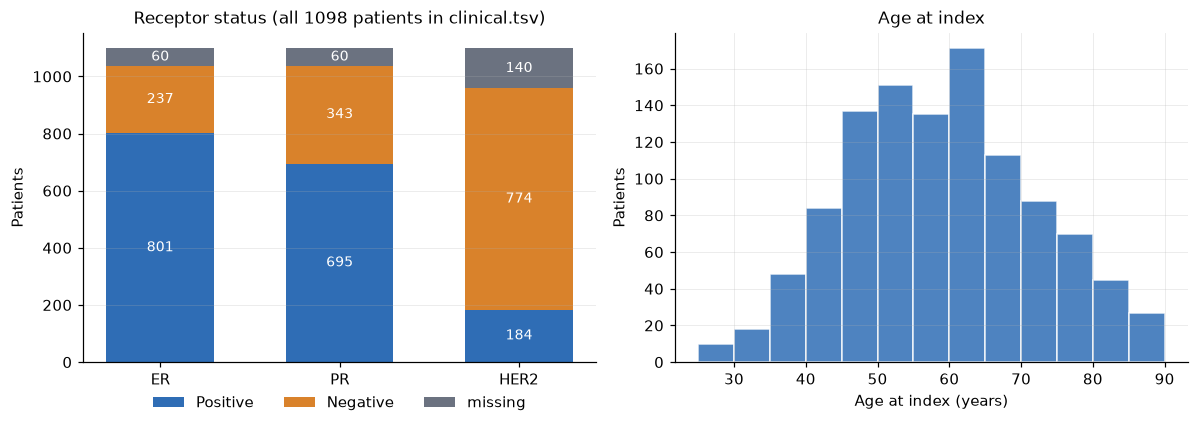

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# (a) availability of each receptor
order = ["Positive", "Negative", "missing"]
av = pd.DataFrame({r: clinical_patient[r].fillna("missing").value_counts() for r in ["ER", "PR", "HER2"]}).reindex(order).fillna(0)
bottom = np.zeros(3)
for lab, col in zip(order, [POS, NEG, GREY]):
    axes[0].bar(av.columns, av.loc[lab], bottom=bottom, color=col, label=lab, width=0.6)
    for x, (b, v) in enumerate(zip(bottom, av.loc[lab])):
        if v > 40: axes[0].text(x, b + v / 2, int(v), ha="center", va="center", color="white", fontsize=9)
    bottom += av.loc[lab].values
axes[0].set_ylabel("Patients"); axes[0].set_title(f"Receptor status (all {len(clinical_patient)} patients in clinical.tsv)")
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3); axes[0].grid(axis="x", visible=False)

# (b) age distribution
axes[1].hist(clinical_patient["age"].dropna(), bins=range(25, 95, 5), color=POS, alpha=0.85, edgecolor="white")
axes[1].set_xlabel("Age at index (years)"); axes[1].set_ylabel("Patients"); axes[1].set_title("Age at index")
fig.tight_layout(); save_fig(fig, "02_clinical_audit"); plt.show()

In [21]:
clinical_patient.to_csv(PROC / "clinical_patient.csv", index=False)
nuclei.reset_index().to_csv(PROC / "tumor_nuclei_by_sample.csv", index=False)
print("Saved clinical_patient.csv", clinical_patient.shape, "and tumor_nuclei_by_sample.csv", nuclei.shape)

Saved clinical_patient.csv (1098, 26) and tumor_nuclei_by_sample.csv (2348,)


**Result.** One clinical row per patient from the primary diagnosis. ER and PR are known for most patients, HER2 for fewer; the main reasons for a missing HER2 are *no test recorded* and *equivocal without definite FISH* (table in section 4). Receptor timing cannot be verified from the file (limitation).